# Import Libraries

In [6]:
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import distance

import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from scipy.optimize import minimize
from scipy.stats import norm

# Initialize Variables 

In [7]:
# Lab Setup
n_samples = 10
max_well_volume = 250
seed = np.random.seed(0)

# Target Color
max_RGB = 255
target_color = [75, 46, 131]
target_color_norm_RGB = np.array(target_color)/max_RGB

def RGB_to_CMYK(RGB_sample):

    Red = RGB_sample[0]
    Green = RGB_sample[1]
    Blue = RGB_sample[2]

    Black = min(1-Red,1-Green,1-Blue)
    Cyan = (1-Red-Black)/(1-Black)
    Magenta = (1-Green-Black)/(1-Black)
    Yellow  = (1-Blue-Black)/(1-Black) 

    return np.array([Cyan, Magenta, Yellow, Black])

target_color_norm_CMYK = RGB_to_CMYK(target_color_norm_RGB)

# Latin Hypercube Sampling

In [8]:
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint, seed):
    # Step 1: Generate Latin Hypercube Samples
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')

    # Step 2: Transform samples to satisfy the sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

def CMYK_to_RGB(cyan_percent, magenta_percent, yellow_percent, black_percent):
    R = (1 - cyan_percent) * (1-black_percent)
    G = (1 - magenta_percent) * (1-black_percent)
    B = (1 - yellow_percent) * (1-black_percent)

    return np.array(list(zip(R,G,B)))

df_lhs = pd.DataFrame(latin_hypercube_sum_constraint(n_samples=n_samples, n_variables=4, sum_constraint=max_well_volume,seed=seed),columns=['C','M','Y','K'])

# Convert to CMYK and zip into an array
cyan = np.array(df_lhs['C']/max_well_volume)
magenta = np.array(df_lhs['M']/max_well_volume)
yellow = np.array(df_lhs['Y']/max_well_volume)
black = np.array(df_lhs['K']/max_well_volume)

sample_CMYK_norm = np.array(list(zip(cyan, magenta, yellow, black)))
sample_RGB_norm = CMYK_to_RGB(cyan, magenta, yellow, black)

### Visualize LHS

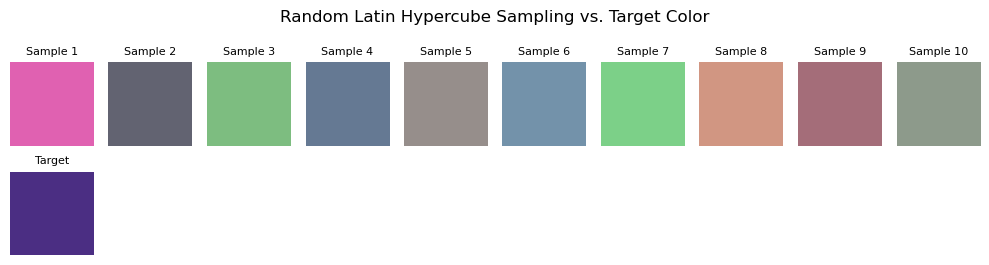

In [9]:
# Visualize the color combinations chosen by the algorithm over iterations.
if (n_samples+1) / 10 > 1:
    colors_per_row = 10  # Limit to 10 colors per row
else:
    colors_per_row = n_samples + 1

n_rows = (n_samples + colors_per_row) // colors_per_row  # Calculate total rows

plt.figure(figsize=(colors_per_row, n_rows * 1.4))
plt.suptitle('Random Latin Hypercube Sampling vs. Target Color')

for idx, rgb in enumerate(sample_RGB_norm):
    row = idx // colors_per_row
    col = idx % colors_per_row
    # Each color is displayed in its own grid
    plt.subplot(n_rows, colors_per_row, idx + 1)
    plt.imshow([[rgb]], extent=[0, 1, 0, 1])
    plt.axis("off")
    plt.title(f"Sample {idx + 1}", fontsize=8)

idx += 1
row = idx // colors_per_row
col = idx % colors_per_row

# Show target color for reference
plt.subplot(n_rows, colors_per_row, idx + 1)
plt.imshow([[target_color]], extent=[0, 1, 0, 1])
plt.axis("off")
plt.title("Target", fontsize=8)

plt.tight_layout()

### LHS Error

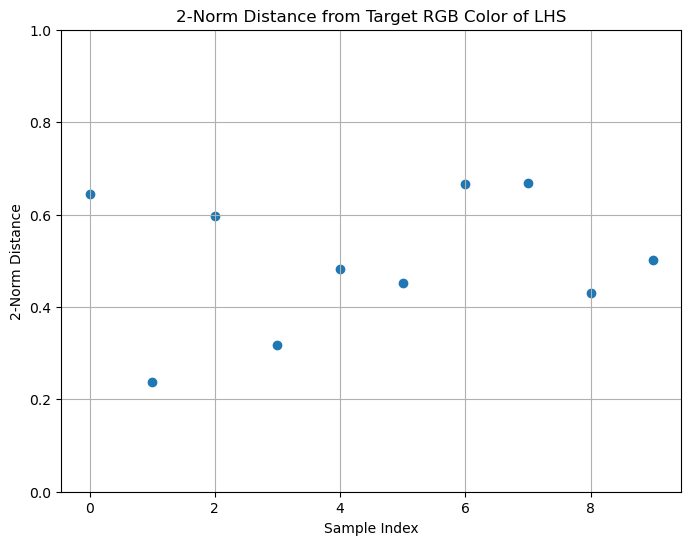

In [10]:
# Calculate the 2-norm distance for each sample color
def norm_error(norm_samples, target_color):

    return [np.linalg.norm(np.array(sample) - target_color) for sample in norm_samples]

sample_distances = norm_error(sample_RGB_norm, target_color_norm_RGB)

# Plot the distances
plt.figure(figsize=(8, 6))
plt.scatter(range(len(sample_RGB_norm)), sample_distances, marker='o')
plt.title('2-Norm Distance from Target RGB Color of LHS')
plt.xlabel('Sample Index')
plt.ylabel('2-Norm Distance')
plt.ylim(0,1)
plt.grid(True)
plt.show()

# Bayesian Optimization

In [11]:
# Optimization Parameters
hyperparameter = 0.01
threshold = 0.025
max_iterations = 20

# Initialize variables
np.random.seed(42)
n_features = 4  # CMYK components
bounds = [(0, 1)] * n_features  # CMYK values are normalized between 0 and 1

# Randomly initialize samples and their corresponding scores
X = sample_CMYK_norm  # Initial mixtures (inputs)
y = -np.linalg.norm(X - target_color_norm_CMYK, axis=1)  # Objective: minimize distance to target color

# Gaussian Process Regression model
kernel = C(constant_value=1, constant_value_bounds=(1e-3, 1e3)) * RBF(length_scale=1, length_scale_bounds=(1e-3, 1e3))
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, alpha=1e-4, normalize_y=False)

## Acquistion Function

In [12]:
# https://ekamperi.github.io/machine%20learning/2021/06/11/acquisition-functions.html

# Expected Improvement maximizes implicetly
def expected_improvement(X, X_sample, y_sample, model):
    """Return the expected improvement.
    Arguments
    mu     -- The predictive mean at the test points.
    sigma -- The predictive standard deviation at
             the test points.
    ymax  -- The maximum observed value (so far).
    """
    mu, sigma = model.predict(X, return_std=True)
    '''No noise is causing sigma to approach 0'''

    optiminal_sample = np.min(y_sample)
    
    with np.errstate(divide="ignore"):
        
        imp = mu - optiminal_sample - hyperparameter
        Z = imp / sigma
        ei = imp * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei.flatten()

# Function to propose the next sample point using Expected Improvement
def propose_location(acquisition, X_sample, y_sample, bounds, n_restarts=25):
    dim = X_sample.shape[1]

    def min_obj(x):
        return -acquisition(x.reshape(-1, dim), X_sample, y_sample, gp)

    # Starting points for optimization
    x0_list = np.random.uniform(0, 1, size=(n_restarts, dim))
    best_x, best_val = None, float("inf")
    for x0 in x0_list:
        res = minimize(min_obj, x0, bounds=bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x
    return best_x

In [13]:
# Run Bayesian Optimization and visualize

distances = []  # Track distances to the target
X_samples = []  # Start with the first sample

for i in range(max_iterations):
    gp.fit(X, y)  # Fit GP model
    
    # Propose the next sampling point
    X_next = propose_location(expected_improvement, X, y, bounds)
    
    # Evaluate the objective function for the new sample
    y_next = -np.linalg.norm(X_next - target_color_norm_CMYK)
    distances.append(-y_next)  # Track the negative distance (closer to target)
    
    # Append the new sample to the dataset
    X = np.vstack((X, X_next))
    y = np.append(y, y_next)
    
    # Track the selected color
    X_samples.append(X_next)

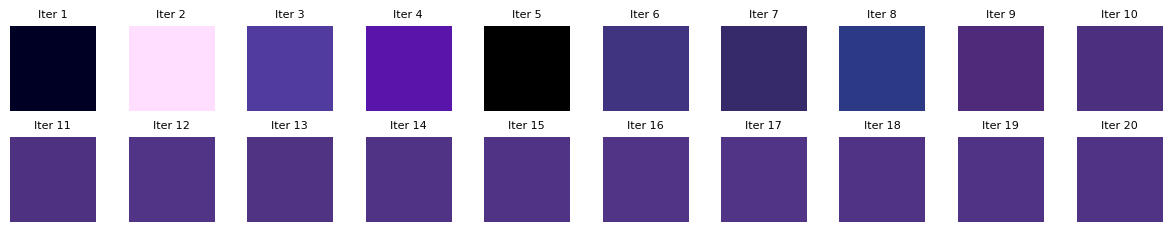

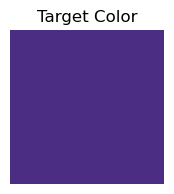

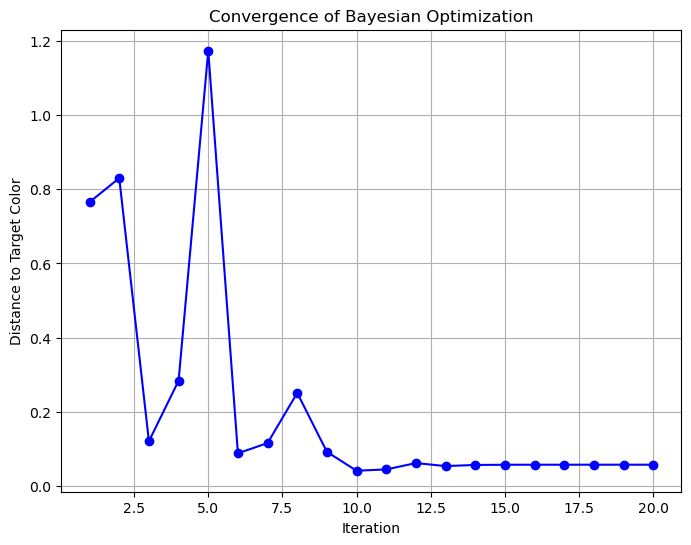

Closest distance to target color: 0.041168078669881474
Optimal CMYK mixture: [0.3965932  0.62764007 0.         0.50332408]
Target CMYK mixture: [0.42748092 0.64885496 0.         0.48627451]


In [15]:
# Visualization of selected colors
def visualize_color_selection(X_samples, target_color):
    """
    Visualize the color combinations chosen by the algorithm over iterations.
    Display colors in a grid with 10 colors per row.
    """
    n_samples = len(X_samples)
    colors_per_row = 10  # Limit to 10 colors per row
    n_rows = (n_samples + colors_per_row - 1) // colors_per_row  # Calculate total rows

    plt.figure(figsize=(12, n_rows * 1.2))
    for idx, rgb in enumerate(X_samples):
        row = idx // colors_per_row
        col = idx % colors_per_row

        # Each color is displayed in its own grid
        plt.subplot(n_rows, colors_per_row, idx + 1)
        plt.imshow([[rgb]], extent=[0, 1, 0, 1])
        plt.axis("off")
        plt.title(f"Iter {idx + 1}", fontsize=8)

    plt.tight_layout()
    
    # Show target color for reference
    plt.figure(figsize=(2, 2))
    plt.imshow([[target_color]], extent=[0, 1, 0, 1])
    plt.axis("off")
    plt.title("Target Color", fontsize=12)
    plt.show()

def column(matrix, i):
    return np.array([row[i] for row in matrix])

X_samples_RGB = CMYK_to_RGB(column(X_samples,0), column(X_samples,1), column(X_samples,2), column(X_samples,3))


# Visualize selected colors
visualize_color_selection(X_samples_RGB, target_color_norm_RGB)

# Plot the convergence
plt.figure(figsize=(8, 6))
plt.plot(range(1, max_iterations + 1), distances, marker='o', linestyle='-', color='b')
plt.title('Convergence of Bayesian Optimization')
plt.xlabel('Iteration')
plt.ylabel('Distance to Target Color')
plt.grid(True)
plt.show()

# Display final results
optimal_rgb = X[np.argmax(y)]
print("Closest distance to target color:", -np.max(y))
print("Optimal CMYK mixture:", optimal_rgb)
print("Target CMYK mixture:", target_color_norm_CMYK)